# Transformasi Geometris Citra Digital
**Nama:** Gilang Budi Iqbal Maliqi
**NIM:** G.211.24.0059
**Mata kuliah:** Pengolahan Citra Digital

## Tujuan
Notebook ini menerapkan tujuh transformasi geometris pada citra yang sama: translasi, rotasi, scaling, shearing, refleksi, affine transform, dan perspective transform. Semua citra input dibaca dari folder `dataset/`, dikonversi menjadi grayscale, lalu hasil disimpan ke `hasil_transformasi/`.

**Catatan dataset:** masukkan minimal 20 citra ke folder `dataset/`. Gunakan kumpulan citra yang sama untuk seluruh jenis transformasi. Format yang didukung: JPG, JPEG, PNG, BMP, TIFF.


## 1. Instalasi dan import pustaka
Jika menjalankan di Google Colab, jalankan sel berikut. OpenCV digunakan untuk transformasi geometris dan Matplotlib untuk menampilkan hasil.


In [1]:
!pip -q install opencv-python-headless matplotlib pandas

In [4]:
import os
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ==============================================================================
# INTEGRASI GOOGLE DRIVE (JALANKAN DI GOOGLE COLAB)
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

# Ubah path ke lokasi folder di Google Drive: "Drive Saya -> Dataset_Gilang"
DATASET_DIR = Path("/content/drive/MyDrive/Dataset_Gilang")
OUTPUT_DIR = Path("/content/drive/MyDrive/hasil_transformasi")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

Mounted at /content/drive


## 2. Memuat minimal 20 citra dan mengubah ke grayscale
Taruh semua citra di folder `dataset/`. Kode memvalidasi jumlah citra, membaca citra berwarna, lalu mengonversinya ke grayscale. Jika citra kurang dari 20 atau file tidak dapat dibaca, program akan menampilkan pesan kesalahan yang jelas.


Berhasil memuat 20 citra grayscale dari '/content/drive/MyDrive/Dataset_Gilang'.
Ukuran citra pertama: (256, 256)


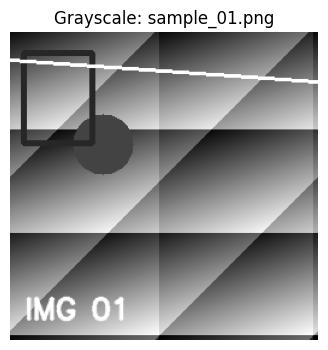

In [5]:
def load_grayscale_images(dataset_dir=DATASET_DIR, min_images=20):
    """Baca citra dari folder dan kembalikan daftar (nama_file, citra_grayscale)."""
    dataset_dir = Path(dataset_dir)
    if not dataset_dir.exists():
        raise FileNotFoundError(
            f"Folder '{dataset_dir}' belum ditemukan. Pastikan folder 'Dataset_Gilang' sudah ada di Google Drive Anda."
        )

    paths = sorted(
        p for p in dataset_dir.iterdir()
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    if len(paths) < min_images:
        raise ValueError(
            f"Ditemukan {len(paths)} citra. Minimal diperlukan {min_images} citra di folder '{dataset_dir}'."
        )

    images = []
    unreadable = []
    for path in paths:
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            unreadable.append(path.name)
            continue
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        images.append((path.name, gray))

    if unreadable:
        print("Peringatan: file berikut tidak berhasil dibaca:", ", ".join(unreadable))
    if len(images) < min_images:
        raise ValueError(f"Hanya {len(images)} citra berhasil dibaca; minimal {min_images} citra harus terbaca.")

    print(f"Berhasil memuat {len(images)} citra grayscale dari '{dataset_dir}'.")
    return images

# Memuat citra dan menampilkan sampel pertama
images = load_grayscale_images()
print("Ukuran citra pertama:", images[0][1].shape)
plt.figure(figsize=(5, 4))
plt.imshow(images[0][1], cmap="gray")
plt.title(f"Grayscale: {images[0][0]}")
plt.axis("off")
plt.show()

## 3. Fungsi transformasi geometris
Setiap fungsi menerima citra grayscale dan mengembalikan citra hasil transformasi dengan ukuran keluaran yang sama seperti input. Area yang berada di luar citra diisi dengan warna hitam (0).


In [6]:
import cv2
import numpy as np


def translation(image, tx=40, ty=30):
    """Menggeser citra tx piksel ke kanan dan ty piksel ke bawah."""
    h, w = image.shape[:2]
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


def rotation(image, angle=30, scale=1.0):
    """Memutar citra sebesar angle derajat terhadap pusat citra."""
    h, w = image.shape[:2]
    center = (w / 2.0, h / 2.0)
    matrix = cv2.getRotationMatrix2D(center, angle, scale)
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


def scaling(image, scale_x=1.2, scale_y=1.2):
    """Memperbesar atau memperkecil citra dengan faktor skala sumbu x dan y terhadap pusat citra."""
    h, w = image.shape[:2]
    matrix = np.float32([
        [scale_x, 0, (1 - scale_x) * w / 2],
        [0, scale_y, (1 - scale_y) * h / 2],
    ])
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


def shearing(image, shear_x=0.25, shear_y=0.0):
    """Melakukan shearing horizontal dan/atau vertikal."""
    h, w = image.shape[:2]
    matrix = np.float32([
        [1, shear_x, -shear_x * h / 2],
        [shear_y, 1, -shear_y * w / 2],
    ])
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


def reflection(image, axis="horizontal"):
    """Refleksi horizontal (kiri-kanan) atau vertical (atas-bawah)."""
    if axis == "horizontal":
        return cv2.flip(image, 1)
    if axis == "vertical":
        return cv2.flip(image, 0)
    if axis == "both":
        return cv2.flip(image, -1)
    raise ValueError("axis harus 'horizontal', 'vertical', atau 'both'.")


def affine_transform(image):
    """Transformasi affine dari tiga pasang titik sumber dan tujuan."""
    h, w = image.shape[:2]
    source = np.float32([
        [0.15 * w, 0.15 * h],
        [0.85 * w, 0.15 * h],
        [0.15 * w, 0.85 * h],
    ])
    destination = np.float32([
        [0.10 * w, 0.20 * h],
        [0.90 * w, 0.10 * h],
        [0.20 * w, 0.90 * h],
    ])
    matrix = cv2.getAffineTransform(source, destination)
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


def perspective_transform(image):
    """Transformasi perspektif menggunakan empat titik sumber dan empat titik tujuan."""
    h, w = image.shape[:2]
    source = np.float32([[0, 0], [w - 1, 0], [0, h - 1], [w - 1, h - 1]])
    destination = np.float32([
        [0.08 * w, 0.05 * h],
        [0.92 * w, 0.12 * h],
        [0.03 * w, 0.92 * h],
        [0.97 * w, 0.85 * h],
    ])
    matrix = cv2.getPerspectiveTransform(source, destination)
    return cv2.warpPerspective(
        image, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0
    )


TRANSFORMS = {
    "translation": translation,
    "rotation": rotation,
    "scaling": scaling,
    "shearing": shearing,
    "reflection": reflection,
    "affine": affine_transform,
    "perspective": perspective_transform,
}

SyntaxError: unexpected character after line continuation character (1156732701.py, line 2)

## 4. Terapkan seluruh transformasi pada semua citra
Setiap file input diproses dengan tujuh fungsi. Output disimpan dalam subfolder terpisah sehingga mudah diperiksa. Nama file asal dipertahankan dengan awalan jenis transformasi.


In [9]:
def apply_all_transforms(images, output_dir=OUTPUT_DIR):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    records = []

    for transform_name in TRANSFORMS:
        (output_dir / transform_name).mkdir(parents=True, exist_ok=True)

    for filename, gray in images:
        results = {
            "translation": translation(gray, tx=40, ty=30),
            "rotation": rotation(gray, angle=30),
            "scaling": scaling(gray, scale_x=1.2, scale_y=1.2),
            "shearing": shearing(gray, shear_x=0.25, shear_y=0.0),
            "reflection": reflection(gray, axis="horizontal"),
            "affine": affine_transform(gray),
            "perspective": perspective_transform(gray),
        }

        for transform_name, result in results.items():
            output_path = output_dir / transform_name / f"{Path(filename).stem}_{transform_name}.png"
            if not cv2.imwrite(str(output_path), result):
                raise IOError(f"Gagal menyimpan hasil: {output_path}")
            records.append({
                "file_input": filename,
                "transformasi": transform_name,
                "ukuran_output": f"{result.shape[1]}x{result.shape[0]}",
                "file_output": str(output_path)
            })

    summary = pd.DataFrame(records)
    summary.to_csv(output_dir / "ringkasan_hasil.csv", index=False)
    print(f"Selesai: {len(images)} citra × {len(TRANSFORMS)} transformasi = {len(records)} hasil.")
    print(f"Folder output: {output_dir.resolve()}")
    return summary

summary_df = apply_all_transforms(images)
display(summary_df.head(14))


Selesai: 20 citra × 7 transformasi = 140 hasil.
Folder output: /content/drive/MyDrive/hasil_transformasi


,file_input,transformasi,ukuran_output,file_output
0,sample_01.png,translation,256x256,/content/drive/MyDrive/hasil_transformasi/tran...
1,sample_01.png,rotation,256x256,/content/drive/MyDrive/hasil_transformasi/rota...
2,sample_01.png,scaling,256x256,/content/drive/MyDrive/hasil_transformasi/scal...
3,sample_01.png,shearing,256x256,/content/drive/MyDrive/hasil_transformasi/shea...
4,sample_01.png,reflection,256x256,/content/drive/MyDrive/hasil_transformasi/refl...
5,sample_01.png,affine,256x256,/content/drive/MyDrive/hasil_transformasi/affi...
6,sample_01.png,perspective,256x256,/content/drive/MyDrive/hasil_transformasi/pers...
7,sample_02.png,translation,256x256,/content/drive/MyDrive/hasil_transformasi/tran...
8,sample_02.png,rotation,256x256,/content/drive/MyDrive/hasil_transformasi/rota...
9,sample_02.png,scaling,256x256,/content/drive/MyDrive/hasil_transformasi/scal...


## 5. Visualisasi perbandingan hasil
Bagian ini menampilkan satu citra contoh dalam grayscale dan hasil tujuh transformasinya. Semua panel menggunakan citra input yang sama.


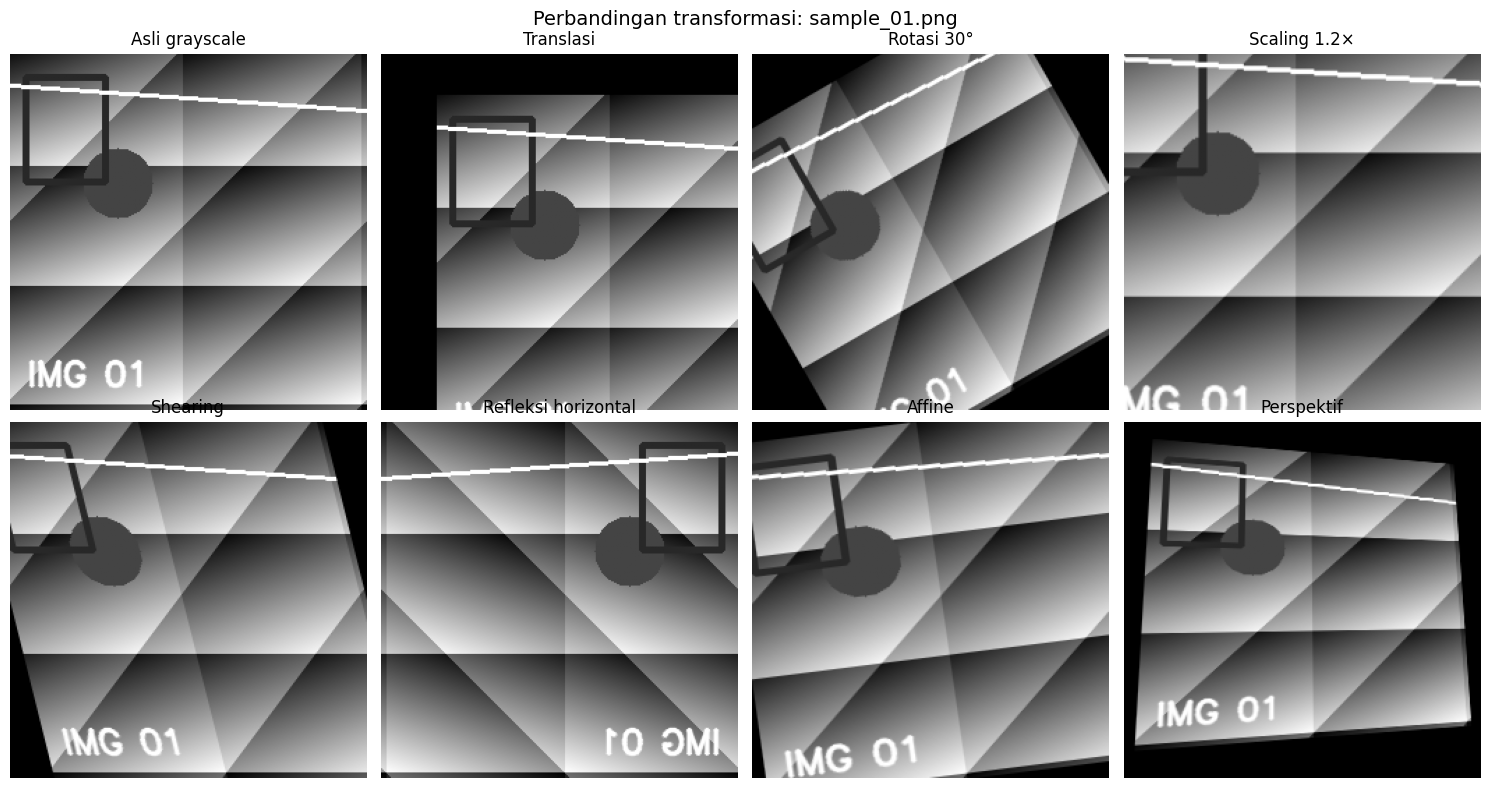

In [8]:
def show_transform_comparison(filename, gray):
    results = [
        ("Asli grayscale", gray),
        ("Translasi", translation(gray)),
        ("Rotasi 30°", rotation(gray, angle=30)),
        ("Scaling 1.2×", scaling(gray, 1.2, 1.2)),
        ("Shearing", shearing(gray, 0.25, 0.0)),
        ("Refleksi horizontal", reflection(gray, "horizontal")),
        ("Affine", affine_transform(gray)),
        ("Perspektif", perspective_transform(gray)),
    ]

    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    for ax, (title, img) in zip(axes.flat, results):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"Perbandingan transformasi: {filename}", fontsize=14)
    plt.tight_layout()
    plt.show()

show_transform_comparison(images[0][0], images[0][1])


## 6. Evaluasi jumlah output
Dengan 20 citra input, notebook menghasilkan sekurang-kurangnya 140 citra output (20 × 7 transformasi). Jumlah aktual ditampilkan di bawah.


In [10]:
print("Jumlah citra input yang diproses:", len(images))
print("Jumlah jenis transformasi:", len(TRANSFORMS))
print("Jumlah output yang dibuat:", len(summary_df))
print("\nJumlah output per transformasi:")
display(summary_df.groupby("transformasi").size().rename("jumlah_output").reset_index())


Jumlah citra input yang diproses: 20
Jumlah jenis transformasi: 7
Jumlah output yang dibuat: 140

Jumlah output per transformasi:


,transformasi,jumlah_output
0,affine,20
1,perspective,20
2,reflection,20
3,rotation,20
4,scaling,20
5,shearing,20
6,translation,20


## 7. Kesimpulan
Translasi menggeser posisi citra; rotasi memutar citra; scaling mengubah skala; shearing menggeser koordinat secara miring; refleksi membalik citra; transformasi affine menggabungkan operasi linear seperti rotasi, skala, dan shear dengan translasi; sedangkan transformasi perspektif memetakan empat titik bidang ke empat titik tujuan sehingga efek perspektif dapat muncul.

Parameter dapat diubah pada pemanggilan fungsi. Karena ukuran output dipertahankan sama dengan input, sebagian area dapat terpotong atau diisi hitam. Simpan notebook beserta folder dataset atau jelaskan sumber dataset saat mengumpulkan tugas.
